# MINI PROJETO

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Abrindo cada arquivo CSV (cada semestre)
# sep=';' avisa que as colunas são separadas por ponto e vírgula
# decimal=',' transforma vírgula em ponto para o Python conseguir fazer contas
df_2024_1 = pd.read_csv('Preços semestrais - AUTOMOTIVOS_2024.01.csv', sep=';', decimal=',')
df_2024_2 = pd.read_csv('Preços semestrais - AUTOMOTIVOS_2024.02.csv', sep=';', decimal=',')
df_2025_1 = pd.read_csv('Preços semestrais - AUTOMOTIVOS_2025.01.csv', sep=';', decimal=',')
df_2025_2 = pd.read_csv('Preços semestrais - AUTOMOTIVOS_2025.02.csv', sep=';', decimal=',')

# 2. Empilhando os 4 arquivos em uma única tabela chamada 'df'
# ignore_index=True reorganiza a numeração das linhas do zero até o final
df = pd.concat([df_2024_1, df_2024_2, df_2025_1, df_2025_2], ignore_index=True)

# 3. Conferindo o tamanho da tabela final (linhas, colunas) e vendo as 5 primeiras linhas
print("Tamanho da base consolidada:", df.shape)
display(df.head())


Tamanho da base consolidada: (1712267, 16)


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA,01/01/2024,5.68,NaN,R$ / litro,VIBRA
1,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA ADITIVADA,01/01/2024,5.68,NaN,R$ / litro,VIBRA
2,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,DIESEL S10,01/01/2024,5.93,NaN,R$ / litro,VIBRA
3,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,ETANOL,01/01/2024,3.99,NaN,R$ / litro,VIBRA
4,NE,AL,ARAPIRACA,AUTO POSTO SAO FRANCISCO LTDA,12.706.529/0001-04,RUA SAO FRANCISCO,274,NaN,CENTRO,57300-080,GASOLINA,01/01/2024,5.48,NaN,R$ / litro,VIBRA


### Problema 1 — Base consolidada (2024–2025)
* Unificação dos 4 arquivos semestrais da ANP (2024.01, 2024.02, 2025.01 e 2025.02) em uma única base
* O DataFrame final reúne **1.712.267 linhas** e **16 colunas**, com vírgula convertida para decimal e índice reiniciado.

### Problema 2 — Gasolina C por município no RJ
* Avaliamos a média do preço de venda da Gasolina C por cidade no estado do RJ entre 2024 e 2025.
* **Maiores médias:** Três Rios (R$ 6,59), Angra dos Reis (R$ 6,52), Petrópolis (R$ 6,48), Barra do Piraí (R$ 6,38) e Macaé (R$ 6,36).
* **Menores médias:** Teresópolis (R$ 5,51), Itaguaí (R$ 5,60) e Magé (R$ 5,62).
* Interior, serra e litoral sul tendem a ter médias maiores, enquanto áreas mais competitivas/metropolitanas têm médias menores.

Top 10 municípios com maiores preços médios no RJ:


,Municipio,Valor de Venda
0,TRES RIOS,6.59
1,ANGRA DOS REIS,6.52
2,PETROPOLIS,6.48
3,BARRA DO PIRAI,6.38
4,MACAE,6.36
5,NOVA FRIBURGO,6.36
6,ITAPERUNA,6.35
7,CAMPOS DOS GOYTACAZES,6.34
8,CABO FRIO,6.32
9,SAO FRANCISCO DE ITABAPOANA,6.21


Top 5 municípios com menores preços médios no RJ:


,Municipio,Valor de Venda
27,NITEROI,5.76
28,BELFORD ROXO,5.75
29,MAGE,5.62
30,ITAGUAI,5.60
31,TERESOPOLIS,5.51


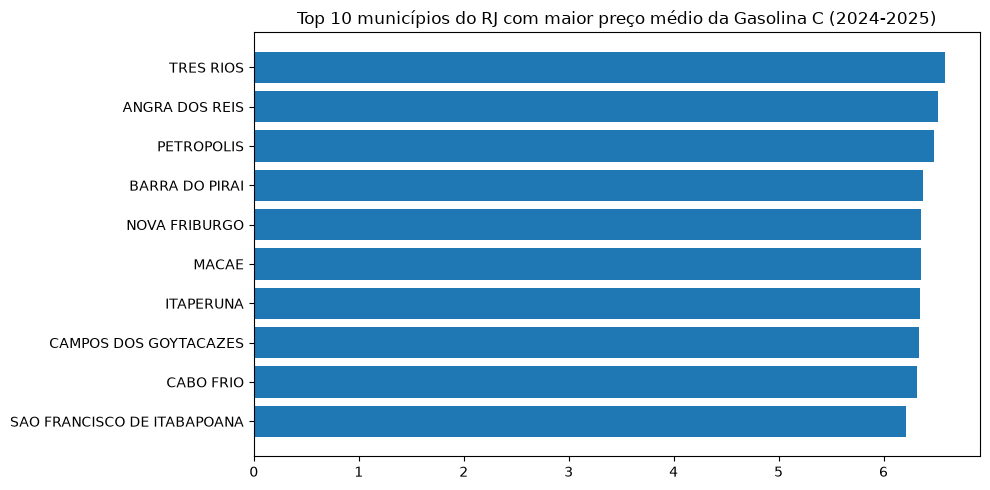

In [102]:
# 1. Filtrando apenas Gasolina no estado do RJ
df_gas_rj = df[(df['Estado - Sigla'] == 'RJ') & (df['Produto'] == 'GASOLINA')].copy()

# 2. Agrupando por Município, calculando a média (.mean()) e ordenando do maior para o menor
media_municipios_rj = (df_gas_rj.groupby('Municipio')['Valor de Venda'].mean().sort_values(ascending=False).reset_index().round(2))

print("Top 10 municípios com maiores preços médios no RJ:")
display(media_municipios_rj.head(10))

print("Top 5 municípios com menores preços médios no RJ:")
display(media_municipios_rj.tail(5))

# Gráfico da Questão 2 (entra logo após media_municipios_rj)
top10_mun = media_municipios_rj.head(10).sort_values(by='Valor de Venda', ascending=True)

plt.figure(figsize=(10, 5))
plt.barh(top10_mun['Municipio'], top10_mun['Valor de Venda'])
plt.title('Top 10 municípios do RJ com maior preço médio da Gasolina C (2024-2025)')
plt.tight_layout()
plt.savefig('nb_q2_barh_municipios.png', dpi=150)
plt.show()

### Problema 3 — Outliers de preço: Gasolina C no RJ
* Com o critério IQR, a faixa normal ficou entre **R$ 5,04** (limite inferior) e **R$ 7,04** (limite superior)
* **Outliers superiores (125 registros):** preços acima de R$ 7,04, chegando a **R$ 7,79** na Barra da Tijuca (Rio de Janeiro)
* **Outliers inferiores (8 registros):** preços abaixo de R$ 5,04, com menor valor em **R$ 4,84** no Jardim Sulacap (Rio de Janeiro)
* **Limite inferior negativo:** quando ocorre, indica assimetria para cima e impossibilidade prática de outlier abaixo de zero em preços

Média: R$ 6.02 | Mediana: R$ 5.99
Q1: R$ 5.79 | Q3: R$ 6.29 | IQR: R$ 0.50
Limite Inferior: R$ 5.04 | Limite Superior: R$ 7.04

Quantidade de registros muito caros (Outliers Superiores): 125


,Municipio,Bairro,Revenda,Data da Coleta,Valor de Venda
564996,RIO DE JANEIRO,BARRA DA TIJUCA,POSTO JARDIM OCEANICO LTDA.,06/08/2024,7.79
677178,RIO DE JANEIRO,BARRA DA TIJUCA,POSTO JARDIM OCEANICO LTDA.,24/09/2024,7.79
724765,RIO DE JANEIRO,BARRA DA TIJUCA,POSTO JARDIM OCEANICO LTDA.,15/10/2024,7.79
695386,RIO DE JANEIRO,BARRA DA TIJUCA,POSTO JARDIM OCEANICO LTDA.,01/10/2024,7.79
708760,RIO DE JANEIRO,BARRA DA TIJUCA,POSTO JARDIM OCEANICO LTDA.,08/10/2024,7.79
613213,RIO DE JANEIRO,BARRA DA TIJUCA,POSTO JARDIM OCEANICO LTDA.,27/08/2024,7.79
629385,RIO DE JANEIRO,BARRA DA TIJUCA,POSTO JARDIM OCEANICO LTDA.,03/09/2024,7.79
644733,RIO DE JANEIRO,BARRA DA TIJUCA,POSTO JARDIM OCEANICO LTDA.,10/09/2024,7.79
500191,RIO DE JANEIRO,BARRA DA TIJUCA,POSTO JARDIM OCEANICO LTDA.,09/07/2024,7.79
516415,RIO DE JANEIRO,BARRA DA TIJUCA,POSTO JARDIM OCEANICO LTDA.,16/07/2024,7.79



Quantidade de registros muito baratos (Outliers Inferiores): 8


,Municipio,Bairro,Revenda,Data da Coleta,Valor de Venda
48157,RIO DE JANEIRO,JARDIM SULACAP,POSTO DE GASOLINA JARDIM SULACAP LTDA,17/01/2024,4.84
79893,RIO DE JANEIRO,JARDIM SULACAP,POSTO DE GASOLINA JARDIM SULACAP LTDA,30/01/2024,4.84
33910,NITEROI,FONSECA,POSTO ICCAR LTDA,11/01/2024,4.99
2253,NITEROI,FONSECA,POSTO ICCAR LTDA,02/01/2024,4.99
51405,NITEROI,FONSECA,POSTO ICCAR LTDA,18/01/2024,4.99
69151,NITEROI,FONSECA,POSTO ICCAR LTDA,25/01/2024,4.99
97837,RIO DE JANEIRO,JARDIM SULACAP,POSTO DE GASOLINA JARDIM SULACAP LTDA,06/02/2024,4.99
235315,RIO DE JANEIRO,JARDIM SULACAP,POSTO DE GASOLINA JARDIM SULACAP LTDA,28/03/2024,4.99


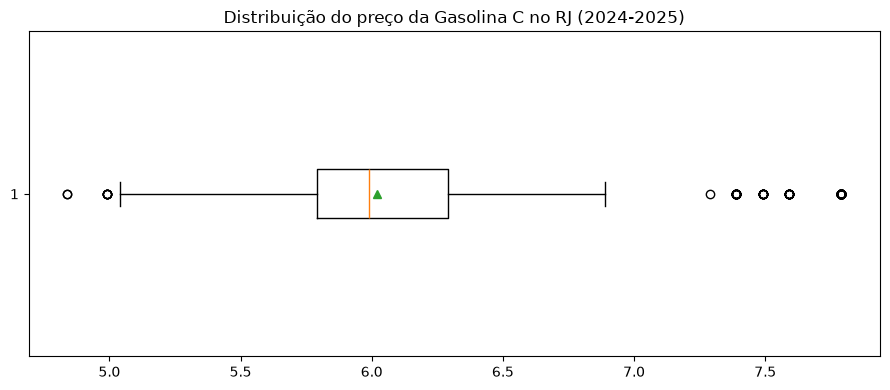

In [103]:
# 1. Pegando a coluna de preços como uma lista numérica
valores_gas_rj = np.array(df_gas_rj['Valor de Venda'])

# 2. Calculando Q1 (25%), Q3 (75%) e o IQR
q1 = np.percentile(valores_gas_rj, 25)
q3 = np.percentile(valores_gas_rj, 75)
iqr = q3 - q1

# 3. Calculando os limites (cercas) inferior e superior
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

print(f"Média: R$ {np.mean(valores_gas_rj):.2f} | Mediana: R$ {np.median(valores_gas_rj):.2f}")
print(f"Q1: R$ {q1:.2f} | Q3: R$ {q3:.2f} | IQR: R$ {iqr:.2f}")
print(f"Limite Inferior: R$ {limite_inferior:.2f} | Limite Superior: R$ {limite_superior:.2f}")

# 4. Filtrando e ordenando os postos fora dos limites
outliers_sup_rj = df_gas_rj[df_gas_rj['Valor de Venda'] > limite_superior].sort_values(by='Valor de Venda', ascending=False)
outliers_inf_rj = df_gas_rj[df_gas_rj['Valor de Venda'] < limite_inferior].sort_values(by='Valor de Venda', ascending=True)

print(f"\nQuantidade de registros muito caros (Outliers Superiores): {len(outliers_sup_rj)}")
display(outliers_sup_rj[['Municipio', 'Bairro', 'Revenda', 'Data da Coleta', 'Valor de Venda']].head(10))

print(f"\nQuantidade de registros muito baratos (Outliers Inferiores): {len(outliers_inf_rj)}")
display(outliers_inf_rj[['Municipio', 'Bairro', 'Revenda', 'Data da Coleta', 'Valor de Venda']].head(10))


# Gráfico
plt.figure(figsize=(9, 4))
plt.boxplot(valores_gas_rj, orientation='horizontal', showmeans=True)
plt.title('Distribuição do preço da Gasolina C no RJ (2024-2025)')
plt.tight_layout()
plt.savefig('nb_q3_boxplot_gasolina_rj.png', dpi=150)
plt.show()

=== ESTADO: SP (Total de coletas: 122691) ===
Média: R$ 3.90 | Mediana: R$ 3.89
Limite Inferior: R$ 3.04 | Limite Superior: R$ 4.72
Outliers Superiores: 2864 | Outliers Inferiores: 2600



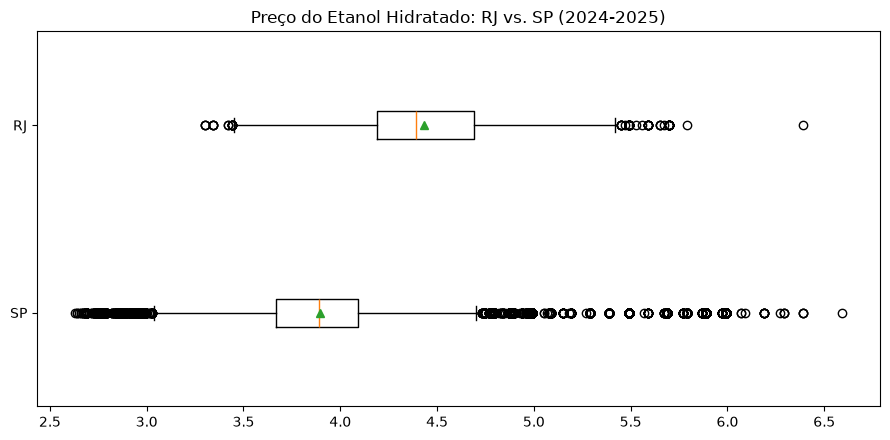

In [104]:
# .isin(['RJ', 'SP']) significa "está dentro dessa lista?"
# Ele verifica cada linha da coluna 'Estado - Sigla' e marca True se for 'RJ' ou 'SP', e False para os outros estados.
# É um atalho mais limpo e fácil de ler do que escrever vários == separados por & (OU).
# Dica: se colocar um ~ na frente (~df['Estado - Sigla'].isin(['RJ', 'SP'])), ele pega tudo, MENOS RJ e SP.
df_etanol = df[(df['Estado - Sigla'].isin(['RJ', 'SP'])) & (df['Produto'] == 'ETANOL')].copy()

# Filtrando apenas Etanol nos estados RJ e SP
df_etanol = df[(df['Estado - Sigla'].isin(['RJ', 'SP'])) & (df['Produto'] == 'ETANOL')].copy()

for estado in ['RJ', 'SP']:
    # Pega os dados apenas daquele estado
    dados_estado = df_etanol[df_etanol['Estado - Sigla'] == estado]
    precos = np.array(dados_estado['Valor de Venda'])

    # Gráfico
vals_rj = np.array(df_etanol[df_etanol['Estado - Sigla'] == 'RJ']['Valor de Venda'].dropna())
vals_sp = np.array(df_etanol[df_etanol['Estado - Sigla'] == 'SP']['Valor de Venda'].dropna())

    
    # Cálculos estatísticos
media = np.mean(precos)
mediana = np.median(precos)
q1 = np.percentile(precos, 25)
q3 = np.percentile(precos, 75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr
    
# Separando os outliers
out_sup = dados_estado[dados_estado['Valor de Venda'] > lim_sup].sort_values(by='Valor de Venda', ascending=False)
out_inf = dados_estado[dados_estado['Valor de Venda'] < lim_inf].sort_values(by='Valor de Venda', ascending=True)

print(f"=== ESTADO: {estado} (Total de coletas: {len(dados_estado)}) ===")
print(f"Média: R$ {media:.2f} | Mediana: R$ {mediana:.2f}")
print(f"Limite Inferior: R$ {lim_inf:.2f} | Limite Superior: R$ {lim_sup:.2f}")
print(f"Outliers Superiores: {len(out_sup)} | Outliers Inferiores: {len(out_inf)}\n")

plt.figure(figsize=(9, 4.5))
plt.boxplot([vals_sp, vals_rj], tick_labels=['SP', 'RJ'], orientation='horizontal', showmeans=True)
plt.title('Preço do Etanol Hidratado: RJ vs. SP (2024-2025)')
plt.tight_layout()
plt.savefig('nb_q4_boxplot_etanol_rj_sp.png', dpi=150)
plt.show()

    

### Problema 4 — Etanol Hidratado: RJ vs. SP
* **RJ:** média de **R$ 4,43** e mediana de **R$ 4,39**, com limites entre **R$ 3,44** e **R$ 5,44** (65 outliers superiores e 17 inferiores).
* **SP:** média de **R$ 3,90** e mediana de **R$ 3,89**, com limites entre **R$ 3,04** e **R$ 4,72** (2.864 outliers superiores e 2.600 inferiores).
* **Conclusão:** os mercados são bem diferentes — SP é mais barato na média e tem muito mais extremos pela escala e diversidade entre interior produtor e áreas caras/rodovias.

Top 10 bairros mais caros da capital:


,Bairro,Valor de Venda
0,FLAMENGO,6.70
1,JARDIM BOTANICO,6.61
2,LAGOA,6.51
3,PARQUE FLAMENGO,6.45
4,ESTACIO,6.42
5,IPANEMA,6.29
6,GÁVEA,6.29
7,GAVEA,6.29
8,VARGEM PEQUENA,6.27
9,LARANJEIRAS,6.24


Top 10 bairros mais baratos da capital:


,Bairro,Valor de Venda
75,MADUREIRA,5.44
76,ANDARAÍ,5.44
77,IRAJA,5.42
78,QUINTINO BOCAIUVA,5.41
79,ROCHA,5.38
80,MEIER,5.34
81,JACARE,5.31
82,MARIA DA GRACA,5.29
83,JARDIM SULACAP,5.23
84,ANIL,5.16


Limite Inferior dos Bairros: R$ 5.01 | Limite Superior: R$ 6.69

Bairros Outliers Superiores:


,Bairro,Valor de Venda
0,FLAMENGO,6.7



Bairros Outliers Inferiores:


,Bairro,Valor de Venda


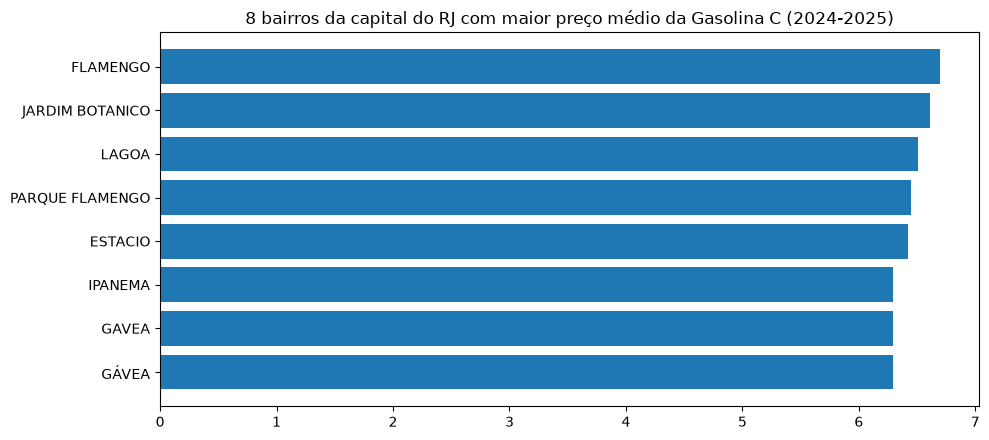

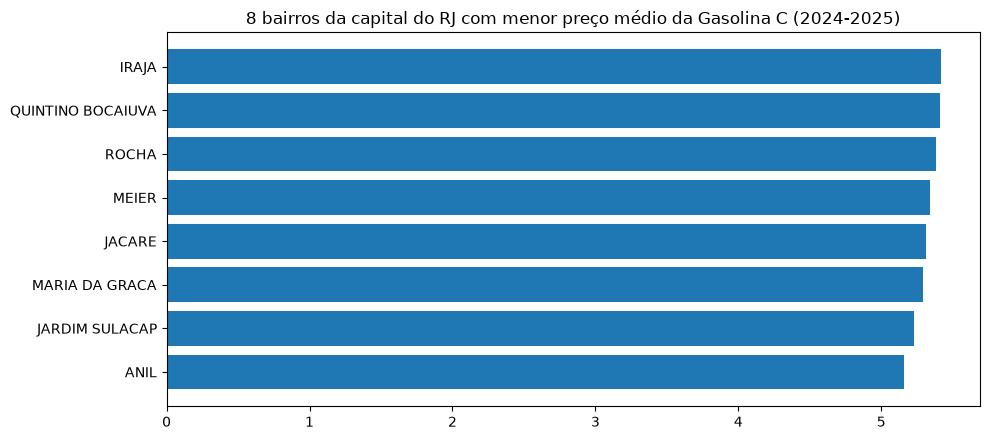

In [105]:
# 1. Filtrando apenas cidade do Rio de Janeiro e produto Gasolina
df_capital_gas = df[(df['Estado - Sigla'] == 'RJ') & (df['Municipio'] == 'RIO DE JANEIRO') & (df['Produto'] == 'GASOLINA')].copy()

# 2. Calculando a média de preço por Bairro e ordenando do maior para o menor
media_bairros = (df_capital_gas.groupby('Bairro')['Valor de Venda'].mean().sort_values(ascending=False).reset_index().round(2))

print("Top 10 bairros mais caros da capital:")
display(media_bairros.head(10))

print("Top 10 bairros mais baratos da capital:")
display(media_bairros.tail(10))

# 3. Aplicando o IQR sobre as médias dos bairros
valores_bairros = np.array(media_bairros['Valor de Venda'])
q1_b = np.percentile(valores_bairros, 25)
q3_b = np.percentile(valores_bairros, 75)
iqr_b = q3_b - q1_b
lim_inf_b = q1_b - 1.5 * iqr_b
lim_sup_b = q3_b + 1.5 * iqr_b

print(f"Limite Inferior dos Bairros: R$ {lim_inf_b:.2f} | Limite Superior: R$ {lim_sup_b:.2f}")

# 4. Identificando bairros outliers
out_bairros_sup = media_bairros[media_bairros['Valor de Venda'] > lim_sup_b]
out_bairros_inf = media_bairros[media_bairros['Valor de Venda'] < lim_inf_b]

print("\nBairros Outliers Superiores:")
display(out_bairros_sup)

print("\nBairros Outliers Inferiores:")
display(out_bairros_inf)

# Gráfico 5A: 8 bairros da capital com maior preço médio
top8_bairros = media_bairros.head(8).sort_values(by='Valor de Venda', ascending=True)

plt.figure(figsize=(10, 4.5))
plt.barh(top8_bairros['Bairro'], top8_bairros['Valor de Venda'])
plt.title('8 bairros da capital do RJ com maior preço médio da Gasolina C (2024-2025)')
plt.tight_layout()
plt.savefig('nb_q5a_top8_bairros.png', dpi=150)
plt.show()

# Gráfico 5B: 8 bairros da capital com menor preço médio
bottom8_bairros = media_bairros.tail(8).sort_values(by='Valor de Venda', ascending=True)

plt.figure(figsize=(10, 4.5))
plt.barh(bottom8_bairros['Bairro'], bottom8_bairros['Valor de Venda'])
plt.title('8 bairros da capital do RJ com menor preço médio da Gasolina C (2024-2025)')
plt.tight_layout()
plt.savefig('nb_q5b_bottom8_bairros.png', dpi=150)
plt.show()



### Problema 5 — Bairros da capital do RJ (Gasolina C)
* Calculamos a média por bairro na cidade do RJ e aplicamos o IQR: limites entre **R$ 5,01** e **R$ 6,69**.
* **Outlier superior (1 bairro):** **Flamengo** (R$ 6,70), seguido de Jardim Botânico (R$ 6,61) e Lagoa (R$ 6,51) — reforçando preços altos em **regiões nobres (Zona Sul)**[cite: 11].
* **Outliers inferiores (0 bairros):** nenhum bairro ficou abaixo de R$ 5,01; os mais baratos são Anil (R$ 5,16), Jardim Sulacap (R$ 5,23) e Maria da Graça (R$ 5,29) — **Zona Norte e Zona Oeste** com menor custo/maior concorrência[cite: 11].
* **Ponto de atenção nos dados:** `GÁVEA` e `GAVEA` aparecem separados por acentuação na base original.